# Watch Athena training runs

Reads a job's log from Athena over SSH (the `athena` shortcut in `~/.ssh/config`) and plots it.

- `plot_training(job)`: one run, loss and `eval_loss` against epochs, plus learning rate, gradient norm and speed
- `compare({"cold": job1, "warm": job2})`: several runs on one chart, against steps
- `live([job1, job2])`: refreshes every minute with the queue status and the curves, until the jobs end

`job` is a Slurm job number. Logs are found in `jobs/lina/lina_v2_<job>.log` (`train_v2.job`) or
`jobs/neil_smolvla_<job>.log` (the team's `train_neil.job`). Use the repo's `.venv` as the kernel.

In [1]:
import re
import subprocess
import time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import clear_output

VLA = "/rg/belinkov_prj/qiu.qiqian/vla"
LOGS = [f"{VLA}/jobs/lina/lina_v2_{{job}}.log", f"{VLA}/jobs/neil_smolvla_{{job}}.log"]


def athena(cmd, timeout=60):
    """Run a shell command on Athena and return its output."""
    r = subprocess.run(["ssh", "-o", "BatchMode=yes", "-o", "ConnectTimeout=15", "athena", cmd],
                       capture_output=True, text=True, timeout=timeout)
    return r.stdout


def fetch_log(job):
    """The job's log text, from the first log path that exists ('' if none yet)."""
    paths = " ".join(p.format(job=job) for p in LOGS)
    return athena(f"for f in {paths}; do [ -f $f ] && cat $f && break; done")

In [2]:
TRAIN = re.compile(r"step:(\S+) smpl:\S+ ep:\S+ epch:([\d.]+) loss:([\d.]+) grdn:([\d.]+) lr:([\d.e+-]+) "
                   r"updt_s:([\d.]+) data_s:([\d.]+)")
EVAL = re.compile(r"step (\d+): eval_loss=([\d.]+)")
SUFFIX = {"K": 1e3, "M": 1e6, "B": 1e9}


def _num(s):
    return float(s[:-1]) * SUFFIX[s[-1]] if s[-1] in SUFFIX else float(s)


def parse_log(text):
    """Training lines -> DataFrame (step, epoch, loss, grad_norm, lr, updt_s, data_s); eval lines -> DataFrame.
    LeRobot rounds the logged step ("step:1K"), so steps come from the line number times the log frequency,
    which the first line still shows exactly (step:200, step:100, step:20)."""
    rows = [m.groups() for m in TRAIN.finditer(text)]
    train = pd.DataFrame(rows, columns=["step", "epoch", "loss", "grad_norm", "lr", "updt_s", "data_s"])
    if len(train):
        freq = _num(train.step[0])
        train["step"] = [(i + 1) * freq for i in range(len(train))]
        train = train.astype(float)
    ev = pd.DataFrame([(int(s), float(l)) for s, l in EVAL.findall(text)], columns=["step", "eval_loss"])
    if len(train) and len(ev):  # epoch of each eval, from the training lines
        ev["epoch"] = ev.step.map(lambda s: float(train.epoch.iloc[(train.step - s).abs().argmin()]) * s
                                  / train.step.iloc[(train.step - s).abs().argmin()])
    info = {k: m.group(1) for k, m in (
        ("frames", re.search(r"num_frames=(\d+)", text)), ("episodes", re.search(r"num_episodes=(\d+)", text)),
        ("steps", re.search(r"cfg.steps=(\d+)", text)), ("init", re.search(r"INIT=(\w+)", text)),
        ("node", re.search(r"Job \d+ on (\S+)", text))) if m}
    info["done"] = "End of training" in text
    info["error"] = next((l for l in text.splitlines() if re.search(r"Error|Traceback|CANCELLED|Killed", l)), None)
    return train, ev, info


def load(job):
    return parse_log(fetch_log(job))

In [3]:
def plot_training(job, x="epoch"):
    """One run: loss (and eval_loss) against epochs or steps, plus learning rate, gradient norm and speed."""
    train, ev, info = load(job)
    if train.empty:
        print(f"Job {job}: no training lines yet", "(" + info["error"] + ")" if info.get("error") else "")
        return
    fig, ax = plt.subplots(2, 2, figsize=(13, 7))
    a = ax[0, 0]
    a.plot(train[x], train.loss, label="train loss")
    if len(ev):
        a.plot(ev[x], ev.eval_loss, "o-", label="eval loss (held-out episodes)")
    a.set(xlabel=x, ylabel="loss", yscale="log", title="Loss"); a.legend(); a.grid(alpha=.3)
    ax[0, 1].plot(train.step, train.lr); ax[0, 1].set(xlabel="step", title="Learning rate"); ax[0, 1].grid(alpha=.3)
    ax[1, 0].plot(train.step, train.grad_norm); ax[1, 0].set(xlabel="step", title="Gradient norm"); ax[1, 0].grid(alpha=.3)
    a = ax[1, 1]
    a.plot(train.step, train.updt_s, label="GPU update s/step"); a.plot(train.step, train.data_s, label="data wait s/step")
    a.set(xlabel="step", title="Time per step"); a.legend(); a.grid(alpha=.3)
    last = train.iloc[-1]
    state = "done" if info["done"] else ("ERROR" if info.get("error") else "running")
    left = (float(info.get("steps", last.step)) - last.step) * (last.updt_s + last.data_s) / 60
    fig.suptitle(f"Job {job} {info.get('init', '')} | {state} | step {last.step:.0f}/{info.get('steps', '?')} "
                 f"epoch {last.epoch:.1f} | loss {last.loss:.3f}"
                 + (f" | eval {ev.eval_loss.iloc[-1]:.3f}" if len(ev) else "")
                 + (f" | ~{left:.0f} min left" if state == "running" else "")
                 + f" | {info.get('episodes', '?')} episodes, {info.get('frames', '?')} frames")
    fig.tight_layout(); plt.show()
    return train, ev


def compare(jobs, x="step"):
    """Several runs on one loss chart, e.g. compare({"cold": 267586, "warm": 267587})."""
    fig, a = plt.subplots(figsize=(10, 5))
    for name, job in jobs.items():
        train, ev, _ = load(job)
        if train.empty:
            print(f"{name} ({job}): no training lines yet"); continue
        line, = a.plot(train[x], train.loss, label=f"{name} train")
        if len(ev):
            a.plot(ev[x], ev.eval_loss, "o--", color=line.get_color(), label=f"{name} eval")
    a.set(xlabel=x, ylabel="loss", yscale="log", title="Loss by run"); a.legend(); a.grid(alpha=.3)
    plt.show()

In [4]:
def job_status(jobs):
    """Slurm state of each job: PENDING (and why), RUNNING (node, time), or its final state."""
    ids = ",".join(map(str, jobs))
    out = athena(f"sacct -n -X -P -j {ids} -o JobID,State,Elapsed,NodeList,Reason")
    return {int(l.split("|")[0]): l.split("|")[1:] for l in out.strip().splitlines() if l}


def live(jobs, every=60, x="epoch"):
    """Refresh every `every` seconds until all jobs end. Stop it with the notebook's Stop button."""
    jobs = list(jobs)
    try:
        while True:
            st = job_status(jobs)
            clear_output(wait=True)
            print(time.strftime("%H:%M:%S"), "(refresh every", every, "s)")
            for j in jobs:
                state, elapsed, node, reason = (st.get(j) or ["?", "", "", ""])[:4]
                print(f"  job {j}: {state:10s} {elapsed:>9s}  {node if state != 'PENDING' else 'waiting: ' + reason}")
            for j in jobs:
                if st.get(j, ["PENDING"])[0] != "PENDING":
                    plot_training(j, x)
            if all(st.get(j, ["?"])[0] not in ("PENDING", "RUNNING", "?") for j in jobs):
                print("All jobs ended."); break
            time.sleep(every)
    except KeyboardInterrupt:
        print("Stopped watching (the jobs keep running).")

## green_cup: cold (267612) vs warm (267613)

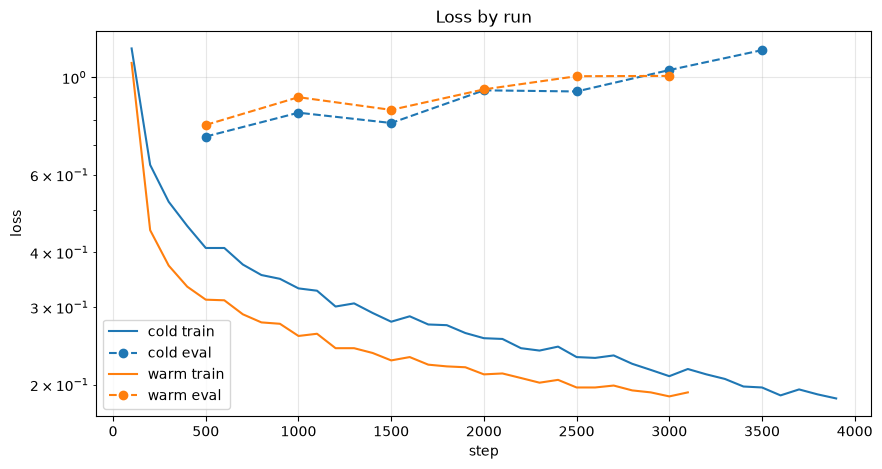

In [5]:
compare({"cold": 267612, "warm": 267613})

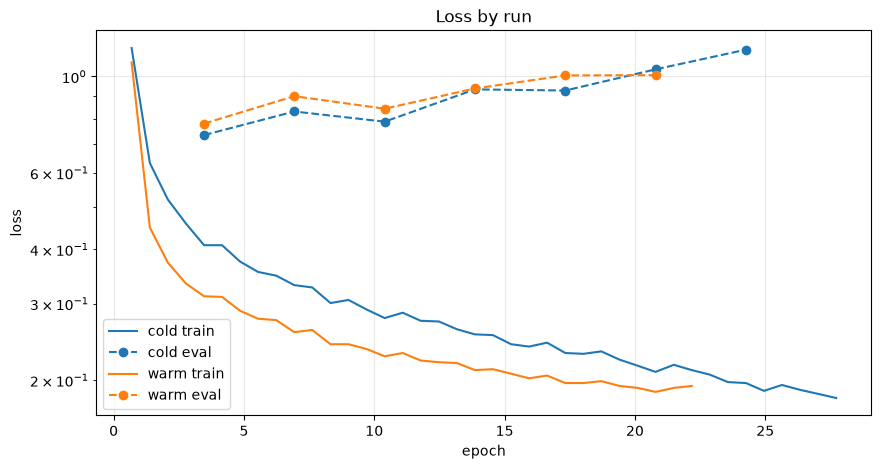

In [6]:
compare({"cold": 267612, "warm": 267613}, x="epoch")

### Cold run (from smolvla_base)

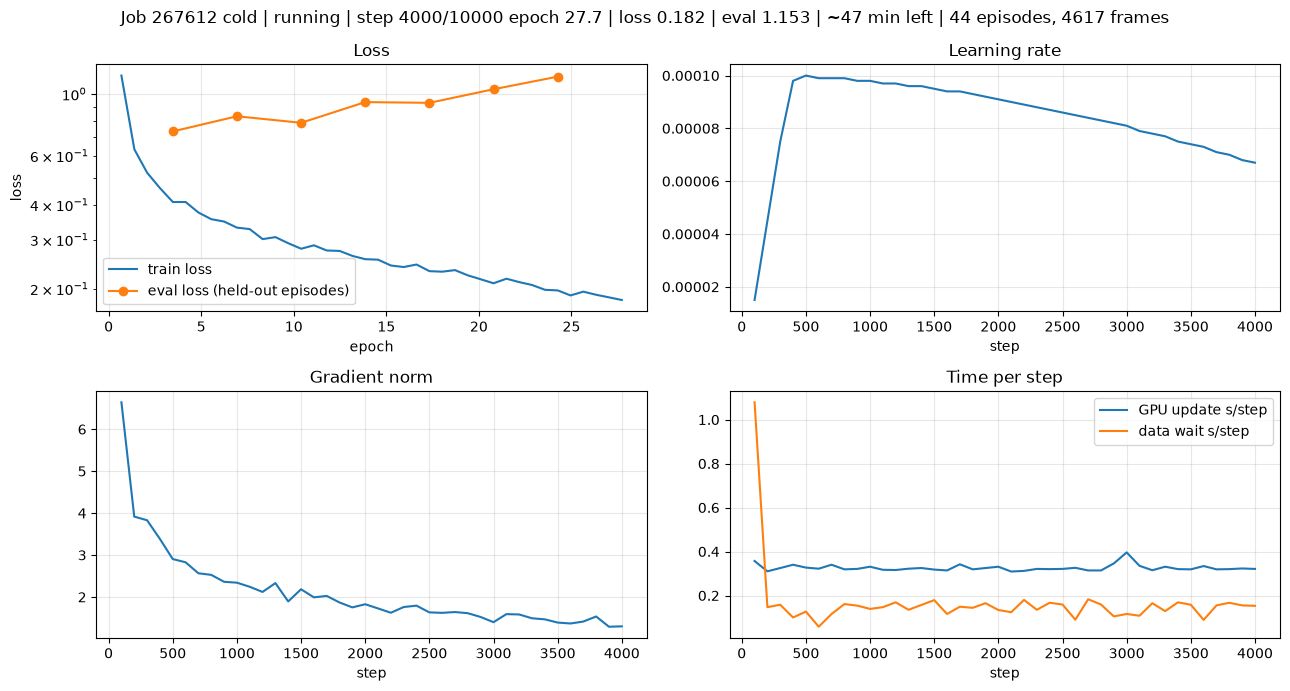

In [7]:
plot_training(267612);

### Warm run (from pos2)

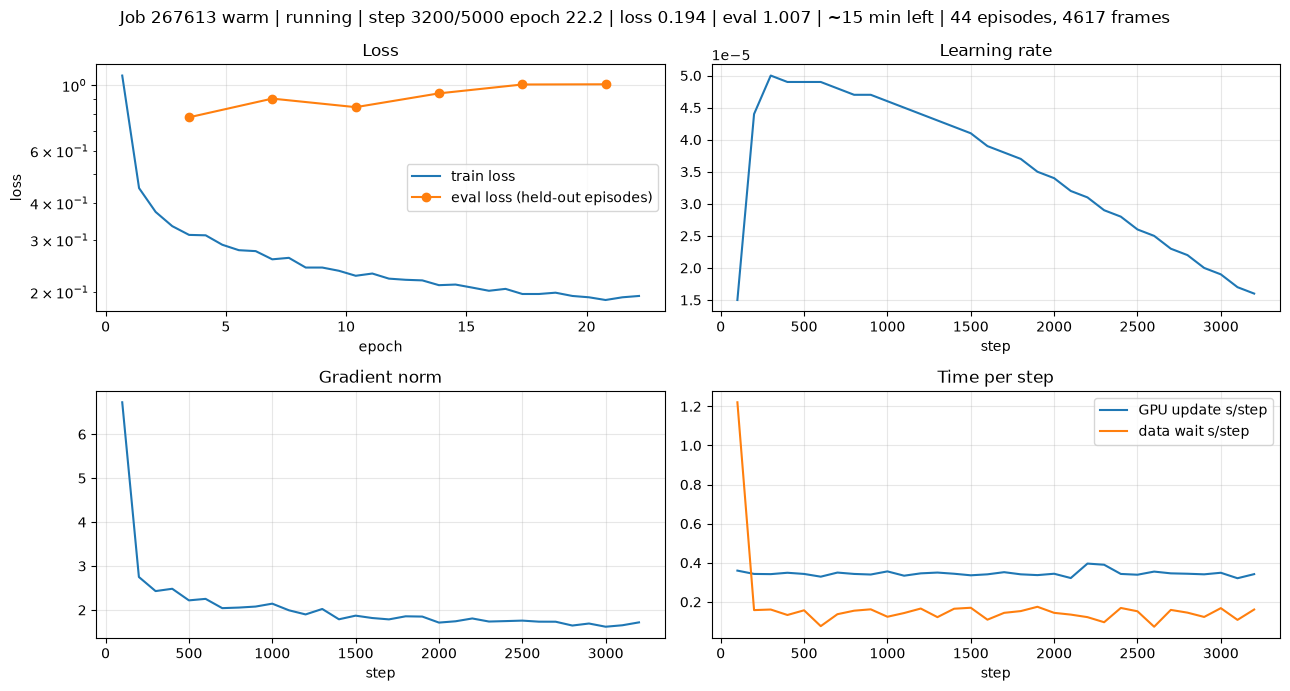

In [8]:
plot_training(267613);

## Live updates (refreshes every minute until both end; Stop button to stop watching)

In [9]:
# live([267612, 267613], every=60)

## Reference: the team's pos2 run (job 181719)

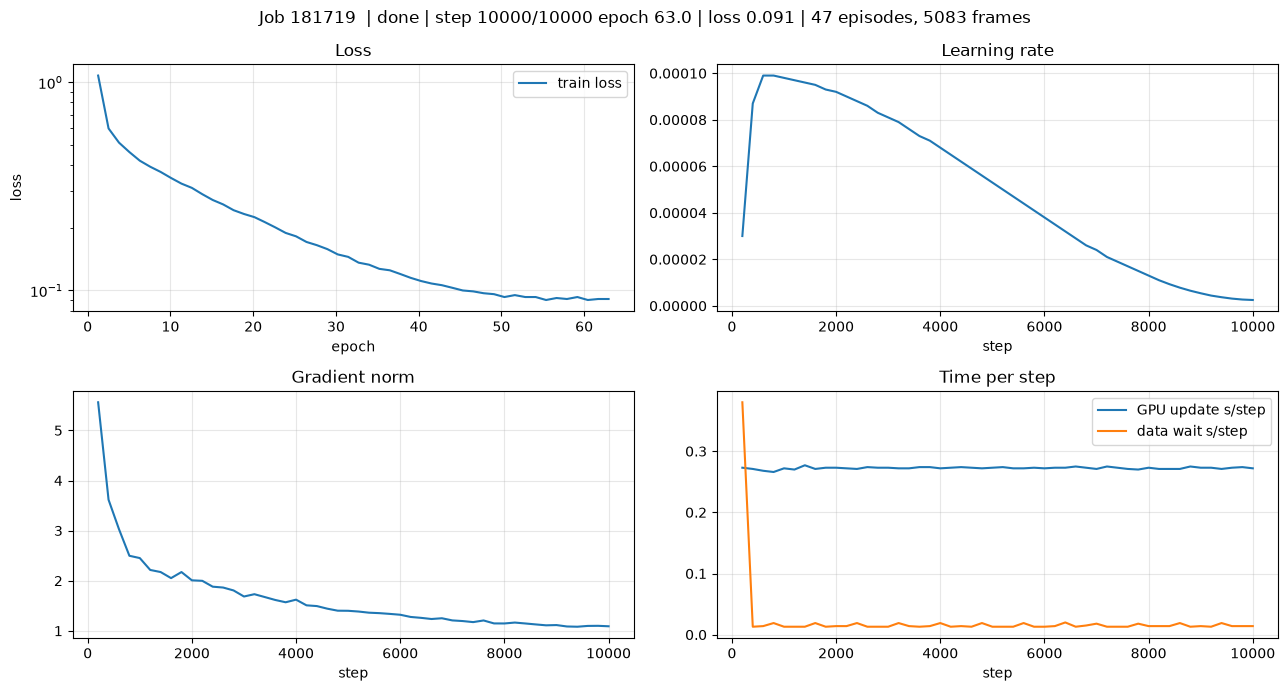

In [10]:
plot_training(181719);